# Sujet 4 · Étude de la file M/M/1

**But.** Comprendre pourquoi une file d'attente à un seul serveur reste sous contrôle ou
s'emballe. On établit d'abord les outils (loi exponentielle, processus de Poisson, simulation
d'une loi de Poisson), puis on simule la file M/M/1 par la récurrence
$L_{n+1} = (L_n + 1 - A_n)^+$ et on compare à la théorie.

Énoncé : [enonce.md](enonce.md) (coquilles signalées) · démonstrations complètes :
[demonstrations.md](demonstrations.md) · Matlab → Python : [matlab_python.md](matlab_python.md) ·
code : `src/stats_td/files_attente.py`. Graine 2026.

Convention : $L_n$ = nombre de clients **présents** (en attente + en service) juste avant
l'arrivée du $n$-ième client ; $\rho = \lambda/\mu$ (et non $\mu/\lambda$, coquille de la Q5).

In [1]:
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path("../../src").resolve()))

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from stats_td.figures import style, sauver, VIOLET, ROUGE, GRIS
from stats_td.generateurs import exponentielle_inversion
from stats_td.empirique import repartition_complementaire
from stats_td.files_attente import (poisson_comptage, file_mm1, longueur_recurrence,
                                    loi_stationnaire, indicateurs_theoriques)

style()
FIG = Path("figures")
rng = np.random.default_rng(2026)  # graine fixée : résultats reproductibles
resultats = {}
virgule = lambda s: s.replace(".", ",")  # nombres à la française dans les figures

## Partie A · La loi exponentielle

**A.1** $E[X] = \sigma_X = 1/\lambda$ (IPP). **A.2** $P(X \ge x + t \mid X \ge x) = e^{-\lambda(x+t)}/e^{-\lambda x}
= e^{-\lambda t} = P(X \ge t)$. **A.3** $G(x) = P(X \ge x)$ vérifie $G(x+t) = G(x)G(t)$ ; $\ln G$ est
additive et monotone, donc linéaire : $G(x) = e^{-\lambda x}$. Preuves :
[demonstrations.md](demonstrations.md#a1).

On tire $10^5$ valeurs de $\mathcal E(2)$ par inversion (Simulation Q1 : $-\ln(1-U)/\lambda$), puis on
regarde la durée de vie **restante** $X - x$ sachant $X \ge x$ pour trois âges $x$. Pour comparer,
on fait la même chose avec une loi **qui a de la mémoire** : Erlang(2), somme de deux $\mathcal E(2)$.

A.1  1/λ = 0.5   moyenne = 0.4976 (-1.51 e.-t.)   écart-type = 0.4986
     test KS contre E(2) : p = 0.15
A.2  expo   P(V >= x + 0.5 | V >= x) pour x = [0.0, 0.5, 1.0] : 0.366  0.368  0.369
A.2  erlang P(V >= x + 0.5 | V >= x) pour x = [0.0, 0.5, 1.0] : 0.735  0.551  0.487
     théorie expo : e^(-λ t) = 0.368 quel que soit x


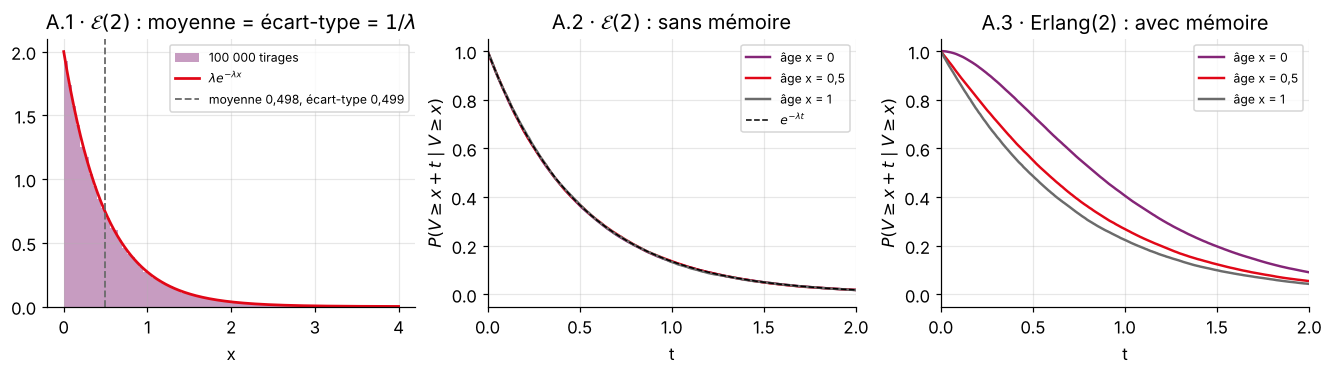

In [2]:
lam, T = 2.0, 100_000
X = exponentielle_inversion(lam, T, rng)        # Simulation Q1 : X = -ln(1 - U) / λ
moy, et = X.mean(), X.std(ddof=1)
z_moy = (moy - 1 / lam) / (et / np.sqrt(T))     # écart à 1/λ en erreurs-types
print(f"A.1  1/λ = {1/lam}   moyenne = {moy:.4f} ({z_moy:+.2f} e.-t.)   écart-type = {et:.4f}")
print(f"     test KS contre E(2) : p = {stats.kstest(X, 'expon', args=(0, 1/lam)).pvalue:.2f}")

# A.2 / A.3 : P(X >= x + t | X >= x) pour plusieurs âges x, exponentielle contre Erlang(2)
Y = exponentielle_inversion(lam, T, rng) + exponentielle_inversion(lam, T, rng)  # Erlang(2)
ages, t0 = [0.0, 0.5, 1.0], 0.5
residuel = {}
for nom, V in [("expo", X), ("erlang", Y)]:
    residuel[nom] = [V[V >= x] - x for x in ages]   # durée de vie restante sachant V >= x
    p = [np.mean(R >= t0) for R in residuel[nom]]
    print(f"A.2  {nom:6s} P(V >= x + {t0} | V >= x) pour x = {ages} : " + "  ".join(f"{v:.3f}" for v in p))
    resultats[f"A_{nom}_residuel_t05"] = p
print(f"     théorie expo : e^(-λ t) = {np.exp(-lam*t0):.3f} quel que soit x")
resultats.update(A_moyenne=moy, A_ecart_type=et, A_z=z_moy, A_lambda=lam)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.3), layout="constrained")
x = np.linspace(0, 4, 300)
axs[0].hist(X, bins=80, range=(0, 4), density=True, color=VIOLET, alpha=0.45, label="100 000 tirages")
axs[0].plot(x, lam * np.exp(-lam * x), color=ROUGE, lw=1.8, label=r"$\lambda e^{-\lambda x}$")
axs[0].axvline(moy, color=GRIS, ls="--", lw=1.2, label=virgule(f"moyenne {moy:.3f}, écart-type {et:.3f}"))
axs[0].set_title(r"A.1 · $\mathcal{E}(2)$ : moyenne = écart-type = $1/\lambda$")
tt = np.linspace(0, 2, 200)
for (nom, titre), ax in zip([("expo", r"A.2 · $\mathcal{E}(2)$ : sans mémoire"),
                             ("erlang", r"A.3 · Erlang(2) : avec mémoire")], axs[1:]):
    for x0, R, c in zip(ages, residuel[nom], [VIOLET, ROUGE, GRIS]):
        r, Fc = repartition_complementaire(R)
        ax.plot(r, Fc, color=c, lw=1.6, label=virgule(f"âge x = {x0:g}"))
    if nom == "expo":
        ax.plot(tt, np.exp(-lam * tt), "k--", lw=1, label=r"$e^{-\lambda t}$")
    ax.set_xlim(0, 2); ax.set_title(titre)
    ax.set_xlabel("t"); ax.set_ylabel(r"$P(V \geq x + t \mid V \geq x)$")
for ax in axs:
    ax.legend(fontsize=8)
axs[0].set_xlabel("x")
sauver(fig, FIG / "s4a_exponentielle.png"); plt.show()

**Lecture.** Moyenne $0{,}498$ et écart-type $0{,}499$, tous deux proches de $1/\lambda = 0{,}5$
(écart de la moyenne : $-1{,}5$ erreur-type, courant ; test KS : $p = 0{,}15$). Pour
l'exponentielle, les trois courbes de survie résiduelle se superposent exactement à $e^{-\lambda t}$ :
à $t = 0{,}5$, $0{,}366$, $0{,}368$ et $0{,}369$ pour les âges 0 ; 0,5 ; 1 (théorie $e^{-1} = 0{,}368$).
L'âge ne change rien : c'est l'absence de mémoire. Pour Erlang(2), la probabilité de durer encore
$0{,}5$ tombe de $0{,}735$ à $0{,}487$ quand l'âge passe de 0 à 1 : la variable « vieillit ». C'est
l'illustration de A.3 : seule l'exponentielle n'a pas de mémoire (pour tous les âges $x$ et durées $t$ réels).

**Figure théorique (sans simulation).** Les mêmes propriétés tracées à partir des formules :
densités de $\mathcal E(\lambda)$ avec leur moyenne $1/\lambda$ ; survie résiduelle
$P(X \ge x + t \mid X \ge x) = G(x+t)/G(x)$ pour trois âges ; et, pour comparer, la loi uniforme sur
$[0, 1]$, où $P(U \ge x + t \mid U \ge x) = \frac{1 - x - t}{1 - x}$ dépend de l'âge $x$.

E(2), t = 0,5 : 0.368 pour tout âge x
uniforme, t = 0,25 : âge 0 -> 0.750  âge 0.25 -> 0.667  âge 0.5 -> 0.500


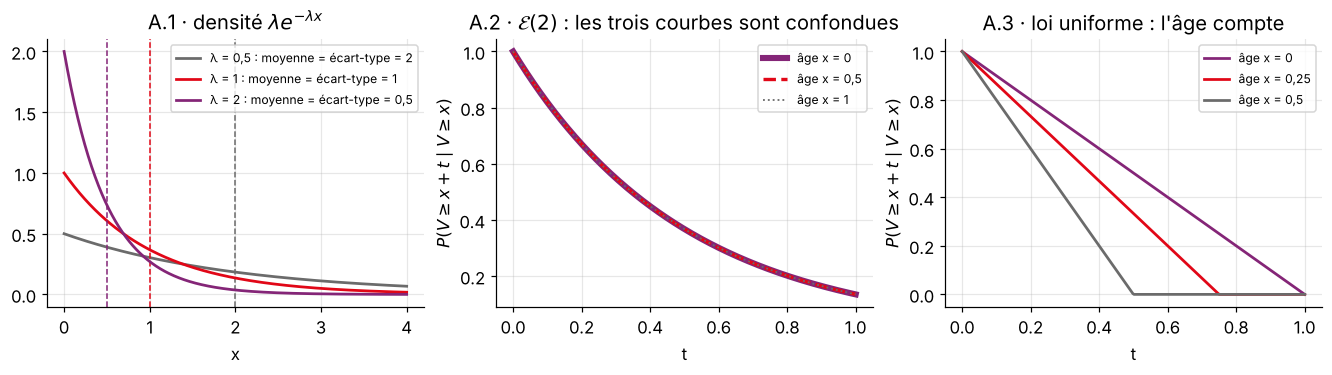

In [3]:
# Figure théorique de la partie A (formules seulement : aucun tirage, rng n'est pas utilisé)
lamA = 2.0
x = np.linspace(0, 4, 400)
t = np.linspace(0, 1, 300)
G = lambda u: np.exp(-lamA * u)                  # P(X >= u) pour E(2)
Gu = lambda u: np.clip(1 - u, 0, 1)              # P(U >= u) pour U uniforme sur [0, 1]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.3), layout="constrained")
for l, c in [(0.5, GRIS), (1.0, ROUGE), (2.0, VIOLET)]:
    axs[0].plot(x, l * np.exp(-l * x), color=c, lw=1.8, label=virgule(f"λ = {l:g} : moyenne = écart-type = {1/l:g}"))
    axs[0].axvline(1 / l, color=c, ls="--", lw=1)
axs[0].set_title(r"A.1 · densité $\lambda e^{-\lambda x}$"); axs[0].set_xlabel("x"); axs[0].legend(fontsize=8)
for x0, c, w, st in [(0.0, VIOLET, 4, "-"), (0.5, ROUGE, 2.2, "--"), (1.0, GRIS, 1.2, ":")]:
    axs[1].plot(t, G(x0 + t) / G(x0), color=c, lw=w, ls=st, label=virgule(f"âge x = {x0:g}"))
axs[1].set_title(r"A.2 · $\mathcal{E}(2)$ : les trois courbes sont confondues")
for x0, c in [(0.0, VIOLET), (0.25, ROUGE), (0.5, GRIS)]:
    axs[2].plot(t, Gu(x0 + t) / Gu(x0), color=c, lw=1.8, label=virgule(f"âge x = {x0:g}"))
axs[2].set_title("A.3 · loi uniforme : l'âge compte")
for ax in axs[1:]:
    ax.set_xlabel("t"); ax.set_ylabel(r"$P(V \geq x + t \mid V \geq x)$"); ax.legend(fontsize=8)
print(f"E(2), t = 0,5 : {G(0.5):.3f} pour tout âge x")
print("uniforme, t = 0,25 : " + "  ".join(f"âge {x0:g} -> {Gu(x0 + 0.25) / Gu(x0):.3f}" for x0 in (0, 0.25, 0.5)))
sauver(fig, FIG / "s4a_theorie.png"); plt.show()

**Lecture.** Pour $\mathcal E(2)$, la probabilité de durer encore $t = 0{,}5$ vaut $e^{-1} = 0{,}368$
quel que soit l'âge. Pour la loi uniforme, la probabilité de durer encore $0{,}25$ passe de $0{,}75$
(âge 0) à $0{,}667$ (âge $0{,}25$) puis $0{,}5$ (âge $0{,}5$) : plus elle a duré, plus la fin est proche.
Elle n'est pas sans mémoire, conformément à A.3.

## Partie B · Processus de Poisson et simulation de $\mathcal P(\lambda)$

**B.1** La densité de $X_1 + X_2$ (indépendantes) est $f * g$ (Fubini). **B.2** Par convolution et
récurrence, $T_k = I_1 + \dots + I_k$ a la densité d'Erlang $f_k(x) = \frac{\lambda^k x^{k-1}}{(k-1)!}e^{-\lambda x}$.
**B.3** $P(N_t = k) = F_k(t) - F_{k+1}(t) = e^{-\lambda t}(\lambda t)^k/k!$ (IPP).
**Simulation Q2** : $N = \sum_i \mathbb 1_{Z_i \le 1}$ compte les points d'un processus de Poisson
dans $[0, 1]$ : on additionne des $\mathcal E(\lambda)$ tant que la somme reste $\le 1$ (fonction
`nombre_points_poisson`).

B.2  T_1 : moyenne 0.4988 (k/λ = 0.5)   KS contre Erlang : p = 0.99
B.2  T_2 : moyenne 1.0011 (k/λ = 1.0)   KS contre Erlang : p = 0.99
B.2  T_5 : moyenne 2.4971 (k/λ = 2.5)   KS contre Erlang : p = 0.64
S.2  P(4) par comptage : moyenne 3.9876, variance 3.9640 (théorie 4 et 4)   chi2 : p = 0.37


B.3  N_3 (λ = 2) : moyenne 5.9948, variance 6.0798 (théorie λt = 6)


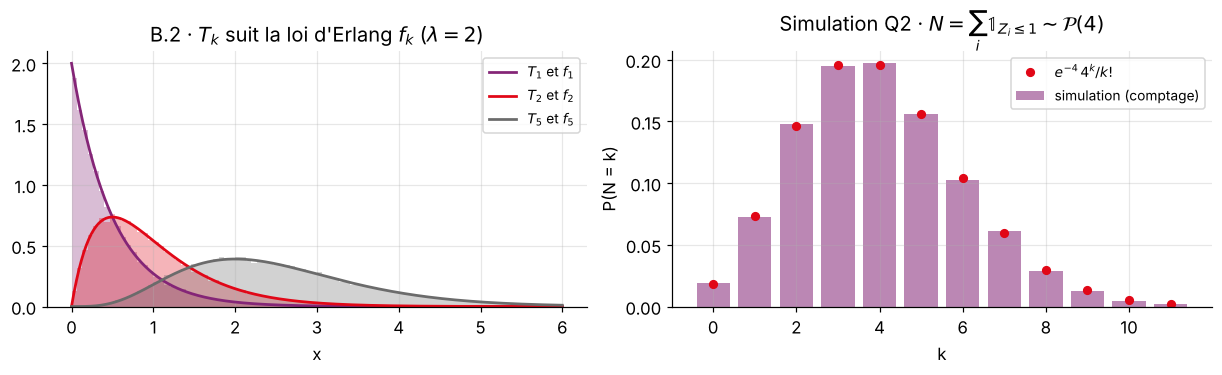

In [4]:
# B.2 : T_k = I_1 + ... + I_k, comparé à la densité d'Erlang f_k
lam, T, kmax = 2.0, 50_000, 5
I = exponentielle_inversion(lam, T * kmax, rng).reshape(T, kmax)
Tk = np.cumsum(I, axis=1)                      # colonne k-1 : instant du k-ième événement
from math import factorial
f = lambda k, x: lam**k * x**(k - 1) / factorial(k - 1) * np.exp(-lam * x)   # densité d'Erlang f_k
for k in (1, 2, 5):
    p_ks = stats.kstest(Tk[:, k - 1], "gamma", args=(k, 0, 1 / lam)).pvalue
    print(f"B.2  T_{k} : moyenne {Tk[:, k-1].mean():.4f} (k/λ = {k/lam})   KS contre Erlang : p = {p_ks:.2f}")

# Simulation Q2 / B.3 : N = somme des 1{Z_i <= 1}, Z_i sommes d'exponentielles E(λ)
lamP, TP = 4.0, 50_000
N = poisson_comptage(lamP, TP, rng)            # algorithme de l'énoncé (comptage)
kk = np.arange(0, 13)
obs = np.array([(N == k).sum() for k in kk[:-1]] + [(N >= kk[-1]).sum()])
th = np.append(stats.poisson.pmf(kk[:-1], lamP), stats.poisson.sf(kk[-1] - 1, lamP))
p_chi2 = stats.chisquare(obs, TP * th).pvalue
print(f"S.2  P(4) par comptage : moyenne {N.mean():.4f}, variance {N.var(ddof=1):.4f} (théorie 4 et 4)"
      f"   chi2 : p = {p_chi2:.2f}")
N3 = poisson_comptage(2.0, 20_000, rng, duree=3.0)  # B.3 : N_t sur [0, 3], λ = 2
print(f"B.3  N_3 (λ = 2) : moyenne {N3.mean():.4f}, variance {N3.var(ddof=1):.4f} (théorie λt = 6)")
resultats.update(B_moy_T5=Tk[:, 4].mean(), P_moyenne=N.mean(), P_variance=N.var(ddof=1),
                 P_chi2=p_chi2, B_N3_moyenne=N3.mean())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), layout="constrained")
x = np.linspace(0, 6, 400)
for k, c in zip((1, 2, 5), (VIOLET, ROUGE, GRIS)):
    axs[0].hist(Tk[:, k - 1], bins=90, range=(0, 6), density=True, color=c, alpha=0.3)
    axs[0].plot(x, f(k, x), color=c, lw=1.8, label=rf"$T_{k}$ et $f_{k}$")
axs[0].set_title(r"B.2 · $T_k$ suit la loi d'Erlang $f_k$ ($\lambda = 2$)"); axs[0].set_xlabel("x")
axs[0].legend(fontsize=9)
axs[1].bar(kk[:-1], obs[:-1] / TP, color=VIOLET, alpha=0.55, label="simulation (comptage)")
axs[1].plot(kk[:-1], th[:-1], "o", color=ROUGE, ms=5, label=r"$e^{-4}\,4^k/k!$")
axs[1].set_title(r"Simulation Q2 · $N=\sum_i \mathbb{1}_{Z_i\leq 1} \sim \mathcal{P}(4)$")
axs[1].set_xlabel("k"); axs[1].set_ylabel("P(N = k)"); axs[1].legend(fontsize=9)
sauver(fig, FIG / "s4b_poisson.png"); plt.show()

**Lecture.** Les histogrammes de $T_1$, $T_2$, $T_5$ suivent les densités d'Erlang (moyennes
$0{,}499$ ; $1{,}001$ ; $2{,}497$ pour $k/\lambda = 0{,}5$ ; $1$ ; $2{,}5$ ; tests KS : $p = 0{,}99$ ;
$0{,}99$ ; $0{,}64$). L'algorithme par comptage donne une loi $\mathcal P(4)$ : moyenne $3{,}99$,
variance $3{,}96$ (les deux valent $\lambda = 4$), test du $\chi^2$ sur la loi complète : $p = 0{,}37$.
Sur $[0, 3]$ avec $\lambda = 2$, $N_3$ a pour moyenne $5{,}99$ (théorie $\lambda t = 6$).

## Q1 · La récurrence $L_{n+1} = (L_n + 1 - A_n)^+$

$N(t)$ est un processus de Poisson d'intensité $\mu$, indépendant des arrivées : ses points sont
les **services potentiels**. Tant que la file n'est pas vide, chaque point fait partir un client
(par absence de mémoire, la durée de service restante est toujours $\mathcal E(\mu)$). Si la file est
vide, le point est perdu. Juste après $T_n$ il y a $L_n + 1$ clients, et $A_n$ points sur
$[T_n, T_{n+1}[$ : il part $\min(A_n, L_n + 1)$ clients, d'où $L_{n+1} = \max(0, L_n + 1 - A_n)$.
Preuve et loi de $A_n$ (géométrique, de moyenne $\mu/\lambda$) : [demonstrations.md](demonstrations.md#m1).

On le vérifie sur une petite trajectoire ($\lambda = 1$, $\mu = 1{,}2$, même charge $\rho = 5/6$ que la
Q5) : on fait évoluer $L(t)$ événement par événement, et on compare avec la récurrence.

n    : [ 1  2  3  4  5  6  7  8  9 10 11 12]
L_n  : [0 0 0 0 0 1 0 1 2 2 1 0]
A_n  : [1 1 6 4 0 2 0 0 1 2 2]
récurrence identique au parcours des événements : True


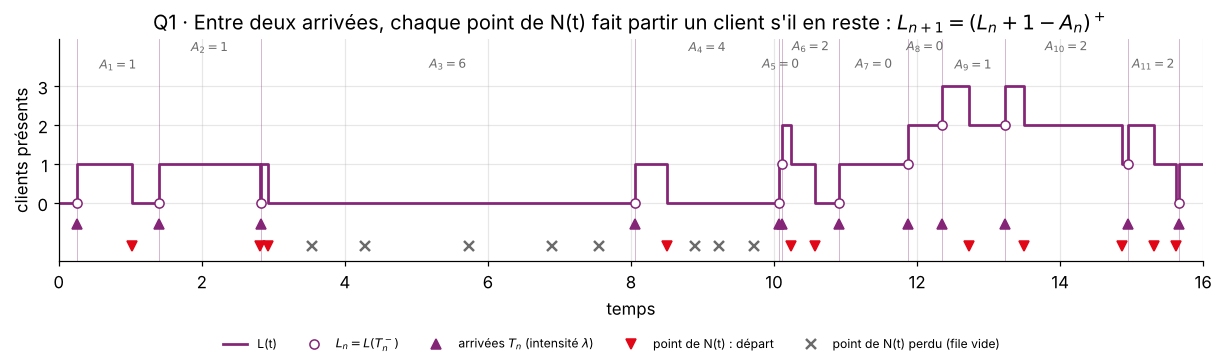

In [5]:
# Q1 : une petite trajectoire en temps continu, construite avec les services potentiels N(t)
lam1, mu1, fin = 1.0, 1.2, 16.0                  # même charge ρ = 5/6 que la Q5, échelle lisible
def instants(intensite, fin):
    t, out = 0.0, []
    while True:
        t += -np.log(1.0 - rng.random()) / intensite
        if t > fin:
            return np.array(out)
        out.append(t)
arr, serv = instants(lam1, fin), instants(mu1, fin)

# Parcours des événements dans l'ordre du temps : arrivée -> +1 ; service potentiel -> -1 si L > 0
ev = sorted([(t, "a") for t in arr] + [(t, "s") for t in serv])
l, temps, niveaux, Ln, depart, perdu = 0, [0.0], [0], [], [], []
for t, e in ev:
    if e == "a":
        Ln.append(l); l += 1                     # L_n = L(T_n^-) : relevé juste avant l'arrivée
    elif l > 0:
        l -= 1; depart.append(t)
    else:
        perdu.append(t)                          # file vide : service potentiel perdu
    temps.append(t); niveaux.append(l)
A = np.diff(np.searchsorted(serv, arr))          # A_n = N(T_{n+1}) - N(T_n)
L_rec = longueur_recurrence(A)                   # L_1 = 0, L_{n+1} = max(0, L_n + 1 - A_n)
print("n    :", np.arange(1, len(arr) + 1))
print("L_n  :", np.array(Ln))
print("A_n  :", A)
print("récurrence identique au parcours des événements :", np.array_equal(L_rec, Ln))
resultats.update(Q1_n=len(arr), Q1_L=list(map(int, Ln)), Q1_A=list(map(int, A)),
                 Q1_perdus=len(perdu))

fig, ax = plt.subplots(figsize=(11, 3.2), layout="constrained")
ax.step(temps + [fin], niveaux + [niveaux[-1]], where="post", color=VIOLET, lw=1.8, label="L(t)")
ax.plot(arr, Ln, "o", color=VIOLET, mfc="white", ms=6, zorder=3, label=r"$L_n = L(T_n^-)$")
for t in arr:
    ax.axvline(t, color=VIOLET, lw=0.6, alpha=0.35)
ax.plot(arr, np.full(len(arr), -0.55), "^", color=VIOLET, ms=7, label=r"arrivées $T_n$ (intensité $\lambda$)")
ax.plot(depart, np.full(len(depart), -1.1), "v", color=ROUGE, ms=7, label="point de N(t) : départ")
ax.plot(perdu, np.full(len(perdu), -1.1), "x", color=GRIS, ms=7, mew=1.6, label="point de N(t) perdu (file vide)")
for n in range(len(A)):                          # A_n au milieu de [T_n, T_{n+1}[, sur deux rangées
    ax.text((arr[n] + arr[n + 1]) / 2, max(niveaux) + 0.45 + 0.45 * (n % 2), f"$A_{{{n+1}}}={A[n]}$",
            ha="center", fontsize=8, color=GRIS)
ax.set_ylim(-1.5, max(niveaux) + 1.2); ax.set_xlim(0, fin)
ax.set_xlabel("temps"); ax.set_ylabel("clients présents")
ax.set_yticks(range(0, max(niveaux) + 1))
fig.legend(fontsize=8, loc="outside lower center", ncol=5, frameon=False)
ax.set_title(r"Q1 · Entre deux arrivées, chaque point de N(t) fait partir un client s'il en reste : $L_{n+1}=(L_n+1-A_n)^+$")
sauver(fig, FIG / "s4_1_recurrence.png"); plt.show()

**Lecture.** Sur cette fenêtre de 12 arrivées, la récurrence redonne exactement les $L_n$ relevés
sur la trajectoire ($0, 0, 0, 0, 0, 1, 0, 1, 2, 2, 1, 0$). Pendant le long creux entre $t = 3$ et
$t = 8$, la file est vide : les points de $N(t)$ (croix grises) sont « perdus ». C'est le sens du
$\max(0, \cdot)$ : entre les arrivées 3 et 4, $A_3 = 6$ services potentiels mais un seul client à
servir.

## Q2 · Algorithme de simulation

```python
def file_mm1(lam, mu, duree, rng):            # src/stats_td/files_attente.py
    T, L = [], []
    t, l = _expo(lam, rng), 0                # T_1, et L_1 = 0 (file vide à t = 0)
    while t <= duree:
        T.append(t); L.append(l)
        s = _expo(lam, rng)                  # T_{n+1} - T_n ~ E(λ)       (Simulation Q1)
        A = nombre_points_poisson(mu, s, rng)  # A_n ~ P(μ s)            (Simulation Q2)
        l = max(0, l + 1 - A)                # récurrence                 (Q1)
        t += s
    return np.array(T), np.array(L)
```
L'algorithme n'utilise que les outils des parties précédentes : l'inversion pour l'écart entre deux
arrivées, le comptage d'exponentielles pour $A_n$ (sachant l'écart $s$, $A_n \sim \mathcal P(\mu s)$
par B.3), et la récurrence de la Q1. On le fait tourner sur les 2 premières secondes avec les
paramètres de la Q5.

226 clients arrivés en 2 s
10 premiers instants T_n (s) : 0.0075 0.0209 0.0263 0.0294 0.0337 0.0444 0.0447 0.0546 0.0766 0.0851
10 premières longueurs L_n   : [0 0 1 2 3 0 1 1 0 0]
plus longue file : 17 ; clients qui trouvent la file vide : 13%


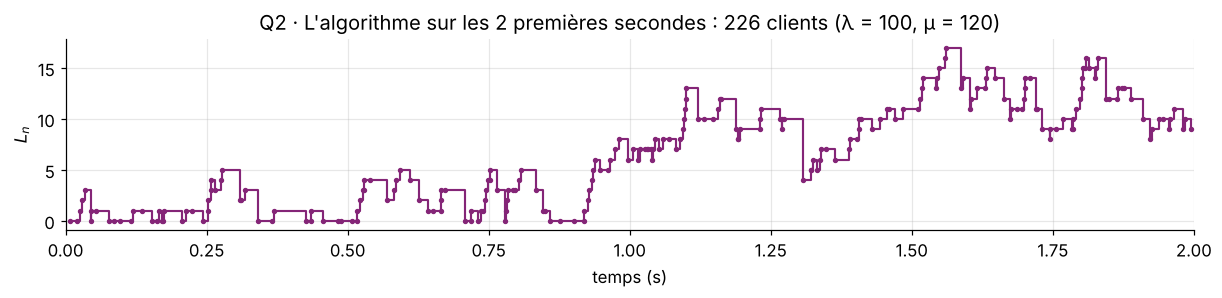

In [6]:
# Q2 : l'algorithme (src/stats_td/files_attente.py, fonction file_mm1), sur les 2 premières secondes
lam, mu = 100.0, 120.0
T2, L2 = file_mm1(lam, mu, 2.0, rng)          # λ = 100 arrivées/s, μ = 120 services/s, file vide au départ
print(f"{len(L2)} clients arrivés en 2 s")
print("10 premiers instants T_n (s) :", " ".join(f"{t:.4f}" for t in T2[:10]))
print("10 premières longueurs L_n   :", L2[:10])
print(f"plus longue file : {L2.max()} ; clients qui trouvent la file vide : {np.mean(L2 == 0):.0%}")
resultats["Q2"] = dict(n=len(L2), premiers_T=T2[:10].tolist(), premiers_L=L2[:10].tolist(),
                       max=int(L2.max()), p0=np.mean(L2 == 0))

fig, ax = plt.subplots(figsize=(11, 2.6), layout="constrained")
ax.step(T2, L2, where="post", color=VIOLET, lw=1.4)
ax.plot(T2, L2, "o", color=VIOLET, ms=2.5)
ax.set_xlabel("temps (s)"); ax.set_ylabel(r"$L_n$"); ax.set_xlim(0, 2)
ax.set_title(f"Q2 · L'algorithme sur les 2 premières secondes : {len(L2)} clients (λ = 100, μ = 120)")
sauver(fig, FIG / "s4_2_algorithme.png"); plt.show()

**Lecture.** 226 clients arrivent en 2 secondes (environ $\lambda \times 2 = 200$). La file part de 0,
monte et redescend : les 10 premiers clients trouvent $0, 0, 1, 2, 3, 0, 1, 1, 0, 0$ personnes devant
eux, et la plus longue file vaut 17. Ces 2 secondes sont trop courtes pour conclure : c'est le rôle
des questions suivantes.

## Q3 · $\rho > 1$ : la file croît indéfiniment

On prend $\lambda = 120$, $\mu = 100$ ($\rho = 1{,}2$), puis une surcharge légère $\lambda = 105$
($\rho = 1{,}05$), pendant 60 s. **Idée** : il arrive $\lambda$ clients par seconde et le serveur en
traite au plus $\mu$ ; si $\lambda > \mu$, la file gagne environ $\lambda - \mu$ clients par seconde.
**Preuve** (formule de Lindley et loi des grands nombres, [demonstrations.md](demonstrations.md#m3)) :
$L_n \ge S_n = \sum_{k<n}(1 - A_k)$ et $S_n/n \to 1 - 1/\rho$, donc $L_n/n \to 1 - 1/\rho$.

ρ = 1.20 : n = 7153   L à 60 s =  1120   pente 19.68 clients/s (théorie λ - μ = 20)   L_n/n = 0.1566 (théorie 1 - 1/ρ = 0.1667)
ρ = 1.05 : n = 6335   L à 60 s =   362   pente  5.15 clients/s (théorie λ - μ = 5)   L_n/n = 0.0571 (théorie 1 - 1/ρ = 0.0476)


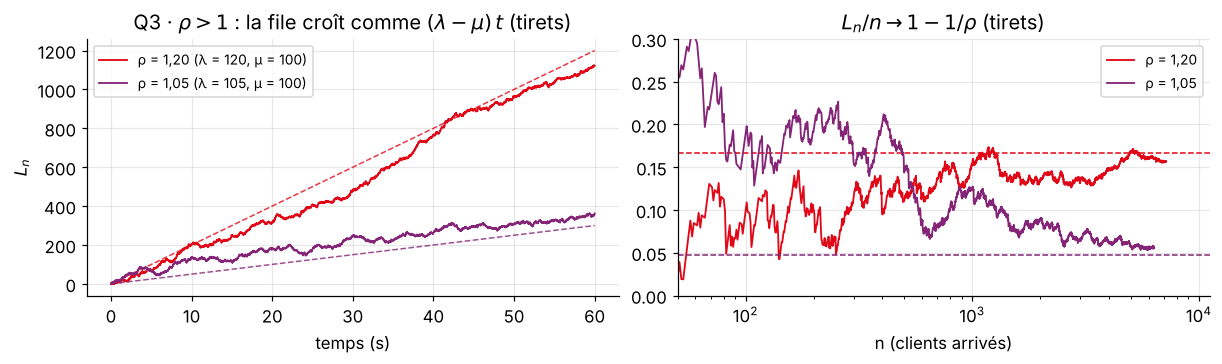

In [7]:
# Q3 : ρ > 1, la file croît sans fin
duree = 60.0
sur = {}
for lam, mu in [(120.0, 100.0), (105.0, 100.0)]:
    Tq, Lq = file_mm1(lam, mu, duree, rng)
    pente_t = np.polyfit(Tq, Lq, 1)[0]                 # clients gagnés par seconde
    sur[lam / mu] = (Tq, Lq)
    print(f"ρ = {lam/mu:.2f} : n = {len(Lq)}   L à 60 s = {Lq[-1]:5d}   pente {pente_t:5.2f} clients/s (théorie λ - μ = {lam-mu:.0f})"
          f"   L_n/n = {Lq[-1]/len(Lq):.4f} (théorie 1 - 1/ρ = {1 - mu/lam:.4f})")
    resultats[f"Q3_rho_{lam/mu:.2f}"] = dict(L_fin=int(Lq[-1]), pente=pente_t, Ln_sur_n=Lq[-1] / len(Lq))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
for (r, (Tq, Lq)), c in zip(sur.items(), (ROUGE, VIOLET)):
    lam = r * 100
    axs[0].plot(Tq, Lq, color=c, lw=1.2, label=virgule(f"ρ = {r:.2f} (λ = {lam:.0f}, μ = 100)"))
    axs[0].plot([0, duree], [0, (lam - 100) * duree], "--", color=c, lw=1, alpha=0.8)
    n = np.arange(1, len(Lq) + 1)
    axs[1].plot(n, Lq / n, color=c, lw=1.2, label=virgule(f"ρ = {r:.2f}"))
    axs[1].axhline(1 - 1 / r, color=c, ls="--", lw=1)
axs[0].set_title(r"Q3 · $\rho > 1$ : la file croît comme $(\lambda-\mu)\,t$ (tirets)")
axs[0].set_xlabel("temps (s)"); axs[0].set_ylabel(r"$L_n$"); axs[0].legend(fontsize=9)
axs[1].set_xscale("log"); axs[1].set_ylim(0, 0.3); axs[1].set_xlim(50, None)
axs[1].set_title(r"$L_n / n \to 1 - 1/\rho$ (tirets)"); axs[1].set_xlabel("n (clients arrivés)")
axs[1].legend(fontsize=9)
sauver(fig, FIG / "s4_3_rho_sup_1.png"); plt.show()

**Lecture.** Avec $\rho = 1{,}2$, la file atteint **1120 clients** au bout d'une minute et croît
d'environ $19{,}7$ clients par seconde (théorie $\lambda - \mu = 20$) ; $L_n/n = 0{,}157$ pour
$1 - 1/\rho = 0{,}167$. Même 5 % de surcharge suffit : $362$ clients après 60 s (pente $5{,}2$/s pour 5),
$L_n/n = 0{,}057$ pour $0{,}048$. La file ne redescend jamais durablement : elle gagne en moyenne
$\lambda - \mu$ clients par seconde.

## Q4 · $\rho < 1$ : la file se stationnarise

On prend $\mu = 100$ et $\lambda = 60$ ($\rho = 0{,}6$) puis $\lambda = 90$ ($\rho = 0{,}9$), pendant
2 minutes. **Idée** : cette fois le serveur traite plus vite qu'il n'arrive de clients, la somme
$S_n = \sum_{k<n}(1 - A_k)$ descend en moyenne (même argument qu'en Q3, avec $1 - 1/\rho < 0$), et la
file revient sans cesse à 0 au lieu de dériver. On regarde la trajectoire et la moyenne cumulée
$\frac1n\sum_{k \le n} L_k$, qui doit se stabiliser sur $\rho/(1-\rho)$ (formule de la Q5).

ρ = 0.6 : n = 7140   moyenne 1.493 (théorie ρ/(1-ρ) = 1.500)   max 14   clients qui trouvent la file vide 0.400 (théorie 1 - ρ = 0.4)
ρ = 0.9 : n = 10920   moyenne 7.926 (théorie ρ/(1-ρ) = 9.000)   max 51   clients qui trouvent la file vide 0.098 (théorie 1 - ρ = 0.1)


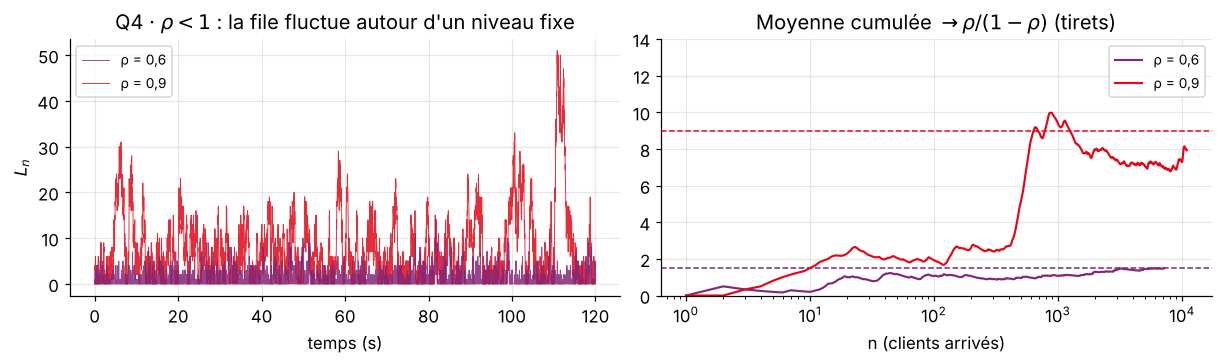

In [8]:
# Q4 : ρ < 1, la file se stationnarise
duree = 120.0
stab = {}
for lam, mu in [(60.0, 100.0), (90.0, 100.0)]:
    Tq, Lq = file_mm1(lam, mu, duree, rng)
    r = lam / mu
    m = Lq.mean()                                      # moyenne de toute la trajectoire
    stab[r] = (Tq, Lq)
    print(f"ρ = {r:.1f} : n = {len(Lq)}   moyenne {m:.3f} (théorie ρ/(1-ρ) = {r/(1-r):.3f})   max {Lq.max()}"
          f"   clients qui trouvent la file vide {np.mean(Lq == 0):.3f} (théorie 1 - ρ = {1-r:.1f})")
    resultats[f"Q4_rho_{r:.1f}"] = dict(n=len(Lq), moyenne=m, max=int(Lq.max()), p0=np.mean(Lq == 0))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
for (r, (Tq, Lq)), c in zip(stab.items(), (VIOLET, ROUGE)):
    axs[0].plot(Tq, Lq, color=c, lw=0.6, alpha=0.85, label=virgule(f"ρ = {r:.1f}"), zorder=3 if r < 0.7 else 2)
    n = np.arange(1, len(Lq) + 1)
    axs[1].plot(n, np.cumsum(Lq) / n, color=c, lw=1.4, label=virgule(f"ρ = {r:.1f}"))
    axs[1].axhline(r / (1 - r), color=c, ls="--", lw=1)
axs[0].set_title(r"Q4 · $\rho < 1$ : la file fluctue autour d'un niveau fixe")
axs[0].set_xlabel("temps (s)"); axs[0].set_ylabel(r"$L_n$"); axs[0].legend(fontsize=9)
axs[1].set_xscale("log"); axs[1].set_ylim(0, 14)
axs[1].set_title(r"Moyenne cumulée $\to \rho/(1-\rho)$ (tirets)"); axs[1].set_xlabel("n (clients arrivés)")
axs[1].legend(fontsize=9)
sauver(fig, FIG / "s4_4_rho_inf_1.png"); plt.show()

**Lecture.** La file revient sans cesse à 0 et ne dérive pas (maxima observés : 14 pour $\rho = 0{,}6$,
51 pour $\rho = 0{,}9$). La moyenne cumulée se stabilise : $1{,}49$ pour $1{,}5$ avec $\rho = 0{,}6$ ; avec
$\rho = 0{,}9$ elle vaut encore $7{,}9$ pour 9 après 2 minutes. Plus $\rho$ est proche de 1, plus le
niveau est haut, plus les excursions sont longues et plus la moyenne met de temps à se stabiliser
(courbe rouge encore bruitée après $10^4$ clients). La part de clients qui trouvent la file vide,
$0{,}400$ et $0{,}098$, est proche de $1 - \rho$ ($0{,}4$ et $0{,}1$).

## Q5 · $\lambda = 100$, $\mu = 120$ pendant 5 minutes

$\rho = 100/120 = 5/6$. Si $P(L = k) = (1-\rho)\rho^k$ (loi géométrique, que l'on vérifie par
simulation), on en déduit ([demonstrations.md](demonstrations.md#m5)) $E[L] = \frac{\rho}{1-\rho} = 5$,
$\operatorname{Var}L = \frac{\rho}{(1-\rho)^2} = 30$, $P(\text{serveur libre}) = P(L = 0) = 1 - \rho = 0{,}167$,
$P(L > 5) = \rho^6 = 0{,}335$.

30155 clients arrivés en 5 min (attendu λ·300 = 30 000) ; plus longue file vue : 51
moyenne          théorie  5.0000   simulation  5.1293   écart relatif +2.6 %
p_serveur_libre  théorie  0.1667   simulation  0.1593   écart relatif -4.4 %
p_plus_de_5      théorie  0.3349   simulation  0.3382   écart relatif +1.0 %
variance         théorie 30.0000   simulation 32.5109   écart relatif +8.4 %
moyenne sans les 10 premières secondes : 5.0579


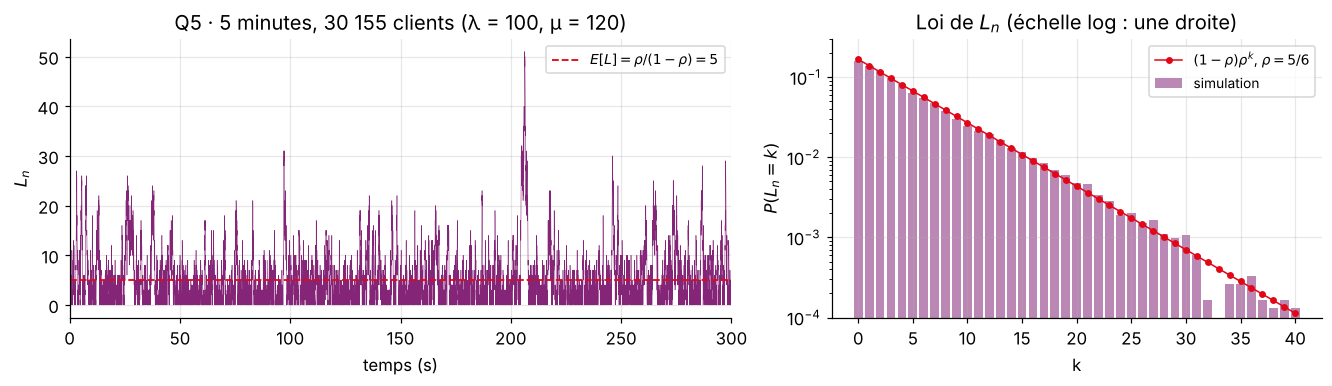

In [9]:
# Q5 : λ = 100 arrivées/s, μ = 120 services/s, 5 minutes à partir d'une file vide
lam, mu, duree = 100.0, 120.0, 300.0
rho = lam / mu                                   # = 5/6 (et non μ/λ : coquille de l'énoncé)
T5, L5 = file_mm1(lam, mu, duree, rng)
th = indicateurs_theoriques(rho)
mesures = {"moyenne": L5, "p_serveur_libre": (L5 == 0), "p_plus_de_5": (L5 > 5)}
print(f"{len(L5)} clients arrivés en 5 min (attendu λ·300 = 30 000) ; plus longue file vue : {L5.max()}")
tableau = {}
for nom, v in mesures.items():
    m = v.mean()                                 # moyenne, ou fréquence pour un booléen
    tableau[nom] = dict(theorie=th[nom], simulation=m, ecart_relatif=(m - th[nom]) / th[nom])
    print(f"{nom:16s} théorie {th[nom]:7.4f}   simulation {m:7.4f}   écart relatif {100*(m - th[nom])/th[nom]:+.1f} %")
var_sim = L5.var(ddof=1)
print(f"{'variance':16s} théorie {th['variance']:7.4f}   simulation {var_sim:7.4f}   écart relatif {100*(var_sim - th['variance'])/th['variance']:+.1f} %")
tableau["variance"] = dict(theorie=th["variance"], simulation=var_sim, ecart_relatif=(var_sim - th["variance"]) / th["variance"])
m10 = L5[T5 > 10].mean()
print(f"moyenne sans les 10 premières secondes : {m10:.4f}")
resultats["Q5"] = dict(n=len(L5), max=int(L5.max()), tableau=tableau, moyenne_sans_10s=m10)

kmax = 40
k = np.arange(kmax + 1)
freq = np.array([np.mean(L5 == j) for j in k])
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained", gridspec_kw=dict(width_ratios=[1.35, 1]))
axs[0].plot(T5, L5, color=VIOLET, lw=0.35)
axs[0].axhline(th["moyenne"], color=ROUGE, ls="--", lw=1.2, label=r"$E[L] = \rho/(1-\rho) = 5$")
axs[0].set_title(f"Q5 · 5 minutes, {len(L5):_} clients (λ = 100, μ = 120)".replace("_", " "))
axs[0].set_xlabel("temps (s)"); axs[0].set_ylabel(r"$L_n$"); axs[0].set_xlim(0, duree)
axs[0].legend(fontsize=9, loc="upper right")
axs[1].bar(k, freq, color=VIOLET, alpha=0.55, label="simulation")
axs[1].plot(k, loi_stationnaire(rho, k), "o-", color=ROUGE, ms=3.5, lw=1, label=r"$(1-\rho)\rho^k$, $\rho = 5/6$")
axs[1].set_yscale("log"); axs[1].set_ylim(1e-4, 0.3)
axs[1].set_title("Loi de $L_n$ (échelle log : une droite)"); axs[1].set_xlabel("k")
axs[1].set_ylabel(r"$P(L_n = k)$"); axs[1].legend(fontsize=9)
sauver(fig, FIG / "s4_5_simulation_5min.png"); plt.show()

**Lecture.** 30 155 clients en 5 minutes. La trajectoire fluctue autour de 5 (pointes jusqu'à
51) sans dériver. La loi empirique de $L_n$ suit la droite $(1-\rho)\rho^k$ en échelle log sur trois
ordres de grandeur. Chiffres :

| quantité | formule | théorie | simulation | écart relatif |
|---|---|---|---|---|
| moyenne | $\rho/(1-\rho)$ | 5 | $5{,}13$ | $+2{,}6$ % |
| variance | $\rho/(1-\rho)^2$ | 30 | $32{,}5$ | $+8{,}4$ % |
| serveur libre | $1-\rho$ | $0{,}167$ | $0{,}159$ | $-4{,}4$ % |
| plus de 5 clients | $\rho^6$ | $0{,}335$ | $0{,}338$ | $+1{,}0$ % |

Les valeurs simulées sont du même ordre de grandeur que la théorie, à quelques pour cent près : une
seule simulation de 5 minutes reste aléatoire. La variance est la plus sensible, car elle dépend des
quelques longues files (jusqu'à 51). Partir d'une file vide ne change presque rien : sans les 10
premières secondes, la moyenne vaut $5{,}06$. En clair : environ un client sur six trouve le serveur
libre, un sur trois trouve plus de 5 personnes devant lui.

## Figure de synthèse · l'influence de la charge

Même algorithme, $\mu = 100$ et $\lambda = 100\rho$, 5 minutes par valeur de $\rho$ : la file moyenne
simulée comparée à $\rho/(1-\rho)$.

ρ = 0.10 : E[L] simulé   0.11   théorie   0.11
ρ = 0.20 : E[L] simulé   0.23   théorie   0.25
ρ = 0.30 : E[L] simulé   0.41   théorie   0.43
ρ = 0.40 : E[L] simulé   0.66   théorie   0.67
ρ = 0.50 : E[L] simulé   1.00   théorie   1.00
ρ = 0.60 : E[L] simulé   1.48   théorie   1.50
ρ = 0.70 : E[L] simulé   2.37   théorie   2.33
ρ = 0.80 : E[L] simulé   4.35   théorie   4.00
ρ = 0.85 : E[L] simulé   6.07   théorie   5.67
ρ = 0.90 : E[L] simulé   8.06   théorie   9.00
ρ = 0.95 : E[L] simulé  17.14   théorie  19.00


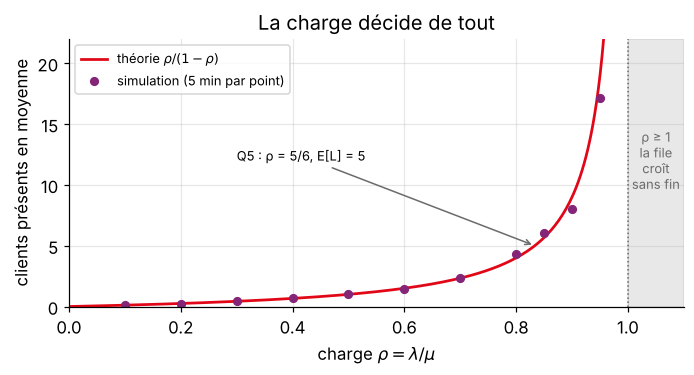

In [10]:
# Figure de synthèse : E[L] en fonction de ρ (μ = 100, 5 minutes simulées par point, même algorithme)
rhos = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95])
EL = np.array([file_mm1(100.0 * r, 100.0, 300.0, rng)[1].mean() for r in rhos])
for r, m in zip(rhos, EL):
    print(f"ρ = {r:.2f} : E[L] simulé {m:6.2f}   théorie {r/(1-r):6.2f}")
resultats["synthese_rho"] = dict(rho=rhos.tolist(), EL=EL.tolist())

fig, ax = plt.subplots(figsize=(6.2, 3.3), layout="constrained")
rr = np.linspace(0, 0.96, 300)
ax.plot(rr, rr / (1 - rr), color=ROUGE, lw=1.8, label=r"théorie $\rho/(1-\rho)$")
ax.plot(rhos, EL, "o", color=VIOLET, ms=5, label="simulation (5 min par point)")
ax.axvspan(1.0, 1.1, color=GRIS, alpha=0.15)
ax.axvline(1.0, color=GRIS, lw=1, ls=":")
ax.text(1.05, 12, "ρ ≥ 1\nla file\ncroît\nsans fin", ha="center", va="center", fontsize=8.5, color=GRIS)
ax.annotate("Q5 : ρ = 5/6, E[L] = 5", xy=(5/6, 5), xytext=(0.3, 12), fontsize=8.5,
            arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set_xlim(0, 1.1); ax.set_ylim(0, 22)
ax.set_xlabel(r"charge $\rho = \lambda/\mu$"); ax.set_ylabel("clients présents en moyenne")
ax.set_title("La charge décide de tout")
ax.legend(fontsize=8.5, loc="upper left")
sauver(fig, FIG / "s4_synthese_rho.png"); plt.show()

**Lecture.** Les points simulés suivent $\rho/(1-\rho)$ (par exemple $1{,}00$ pour 1 à
$\rho = 0{,}5$, $4{,}35$ pour 4 à $\rho = 0{,}8$). La courbe explose quand $\rho \to 1$ : en théorie,
passer de $\rho = 0{,}8$ à $0{,}9$ fait plus que doubler la file moyenne (4 puis 9), et elle vaut 19 à
$0{,}95$. Près de 1, une simulation de 5 minutes s'écarte davantage de la théorie ($8{,}06$ pour 9,
$17{,}1$ pour 19), car la file met plus de temps à se stabiliser (Q4).

In [11]:
def propre(o):  # numpy -> types JSON
    if isinstance(o, dict):
        return {str(k): propre(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [propre(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    return o
(FIG / "resultats.json").write_text(json.dumps(propre(resultats), indent=2, ensure_ascii=False))
print("resultats.json écrit :", ", ".join(resultats))

resultats.json écrit : A_expo_residuel_t05, A_erlang_residuel_t05, A_moyenne, A_ecart_type, A_z, A_lambda, B_moy_T5, P_moyenne, P_variance, P_chi2, B_N3_moyenne, Q1_n, Q1_L, Q1_A, Q1_perdus, Q2, Q3_rho_1.20, Q3_rho_1.05, Q4_rho_0.6, Q4_rho_0.9, Q5, synthese_rho
